<a href="https://colab.research.google.com/github/thrka33/ITA0604-ML/blob/main/ML_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXP 1 : Implement and demonstrate the FIND-S algorithm for finding the most specific hypothesis based on a given set of training data samples.  

In [1]:
data = [
 ['Sunny','Warm','Normal','Strong','Warm','Same','Yes'],
 ['Sunny','Warm','High','Strong','Warm','Same','Yes'],
 ['Rainy','Cold','High','Strong','Warm','Change','No'],
 ['Sunny','Warm','High','Strong','Cool','Change','Yes']]
h = None
for row in data:
    if row[-1] == 'Yes':
        x = row[:-1]
        if h is None: h = x.copy()
        else: h = [a if a == b else '?' for a,b in zip(h,x)]
print("Final hypothesis:", h)


Final hypothesis: ['Sunny', 'Warm', '?', 'Strong', '?', '?']


EXP 2 : For a given set of training data examples stored in a .CSV file, implement and demonstrate the Candidate-Elimination algorithm in python to output a description of the set of all hypotheses consistent with the training examples

In [2]:
import pandas as pd
from io import StringIO
csv = StringIO("""Sky,AirTemp,Humidity,Wind,Water,Forecast,Enjoy
Sunny,Warm,Normal,Strong,Warm,Same,Yes
Sunny,Warm,High,Strong,Warm,Same,Yes
Rainy,Cold,High,Strong,Warm,Change,No
Sunny,Warm,High,Strong,Cool,Change,Yes
""")
df = pd.read_csv(csv)
X, y = df.iloc[:,:-1].values, df.iloc[:,-1].values
S = ['Ø']*X.shape[1]; G = [['?']*X.shape[1]]
for x, label in zip(X,y):
    if label == 'Yes':
        S = [v if s == 'Ø' or s == v else '?' for s,v in zip(S,x)]
        G = [g for g in G if all(a == '?' or a == b for a,b in zip(g,x))]
    else:
        new = []
        for g in G:
            for i,v in enumerate(x):
                if g[i] == '?' and S[i] not in ('Ø','?') and S[i] != v:
                    h = g.copy(); h[i] = S[i]; new.append(h)
        G = new
print("S boundary:", S)
print("G boundary:", G)


S boundary: ['Sunny', 'Warm', '?', 'Strong', '?', '?']
G boundary: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?']]


EXP 3 : Demonstrate the working of the decision tree based ID3 algorithm. Use an appropriate data set for building the decision tree and apply this knowledge to classify a new sample.

|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- petal width (cm) <= 1.65
|   |   |   |   |--- class: 1
|   |   |   |--- petal width (cm) >  1.65
|   |   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- petal width (cm) <= 1.55
|   |   |   |   |--- class: 2
|   |   |   |--- petal width (cm) >  1.55
|   |   |   |   |--- petal length (cm) <= 5.45
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- petal length (cm) >  5.45
|   |   |   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- sepal width (cm) <= 3.10
|   |   |   |   |--- class: 2
|   |   |   |--- sepal width (cm) >  3.10
|   |   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2

Predicted class: setosa


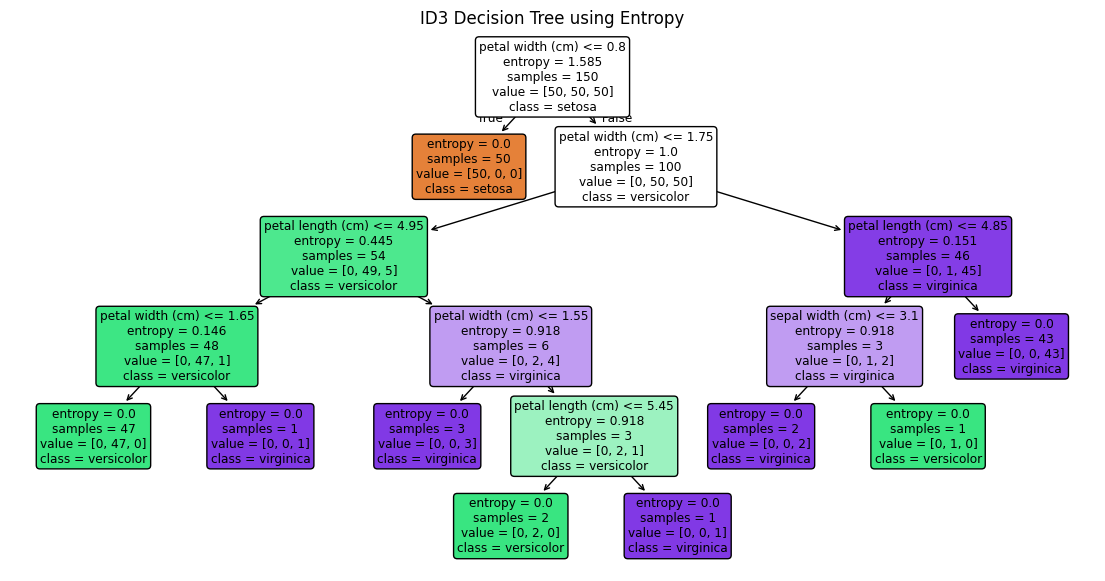

In [6]:

from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
import matplotlib.pyplot as plt

d = load_iris()
m = DecisionTreeClassifier(criterion='entropy', random_state=0)
m.fit(d.data, d.target)

print(export_text(m, feature_names=list(d.feature_names)))
print("Predicted class:",
      d.target_names[m.predict([[5.1, 3.5, 1.4, 0.2]])[0]])

plt.figure(figsize=(14, 7))
plot_tree(m, feature_names=d.feature_names,
          class_names=d.target_names, filled=True, rounded=True)
plt.title("ID3 Decision Tree using Entropy")
plt.show()

EXP 4 : Build an Artificial Neural Network by implementing the Backpropagation algorithm and test the same using appropriate data sets.

Predictions: [0 1 1 0]


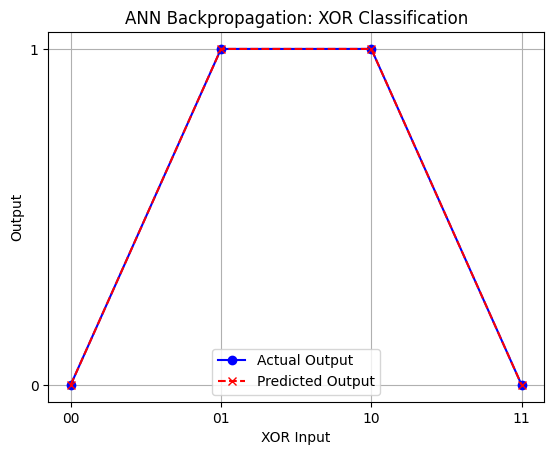

In [7]:

from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt

X = [[0,0], [0,1], [1,0], [1,1]]
y = [0, 1, 1, 0]

m = MLPClassifier(hidden_layer_sizes=(4,), activation='tanh',
                  solver='lbfgs', max_iter=3000, random_state=1)
m.fit(X, y)
pred = m.predict(X)

print("Predictions:", pred)

plt.plot(range(4), y, 'bo-', label='Actual Output')
plt.plot(range(4), pred, 'rx--', label='Predicted Output')
plt.xticks(range(4), ['00', '01', '10', '11'])
plt.yticks([0, 1])
plt.xlabel("XOR Input")
plt.ylabel("Output")
plt.title("ANN Backpropagation: XOR Classification")
plt.legend()
plt.grid(True)
plt.show()

EXP 5:Write a program for Implementation of K-Nearest Neighbours (K-NN) in Python

Prediction: setosa


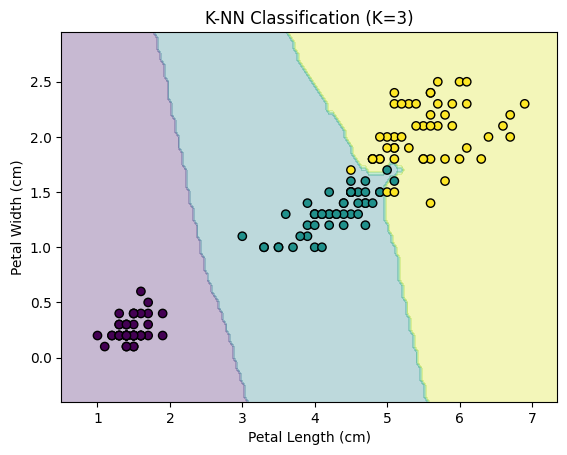

Training accuracy: 0.96


In [8]:

from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import numpy as np

d = load_iris()
X = d.data[:, 2:4]  # Petal length and width
y = d.target

m = KNeighborsClassifier(n_neighbors=3)
m.fit(X, y)

print("Prediction:",
      d.target_names[m.predict([[1.4, 0.2]])[0]])

# Create decision boundary grid
x1, x2 = np.meshgrid(
    np.arange(X[:, 0].min()-0.5, X[:, 0].max()+0.5, 0.05),
    np.arange(X[:, 1].min()-0.5, X[:, 1].max()+0.5, 0.05)
)

Z = m.predict(np.c_[x1.ravel(), x2.ravel()])
Z = Z.reshape(x1.shape)

plt.contourf(x1, x2, Z, alpha=0.3, cmap='viridis')
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='black',
            cmap='viridis')
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("K-NN Classification (K=3)")
plt.show()

# Original four-feature model accuracy
m4 = KNeighborsClassifier(n_neighbors=3).fit(d.data, d.target)
print("Training accuracy:", round(m4.score(d.data, d.target), 2))